# Week 1: Polynomial Terms, Interaction Terms and Multicollinearity
Eric Benaroch, Module C Capstone

Research question from my proposal: does malicious behavior leave the same statistical pattern in different threat domains, or is every domain different?

The three datasets are CICAndMal2017 (Android malware traffic), CICIDS2017 (network attacks) and WELFake (fake news).

This week I apply the lesson to all three:
1. Check for multicollinearity with a correlation matrix and VIF.
2. Fit a basic linear regression.
3. Add polynomial terms and use cross-validation to pick the degree.
4. Add interaction terms with the malicious label to see if malicious data follows a different slope.
5. Show why linear regression is a bad fit for a 0/1 target.

The targets follow Module B: log of Flow Bytes/s for the two network datasets and log of word count for WELFake.

## 1. Setup

In [3]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score

import os
from pathlib import Path
DATA_DIR = Path(os.environ.get("CAPSTONE_DATA_DIR", "."))   # folder with the zips and the WELFake csv
FIG_DIR = Path("figures_week1"); FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 2. Load the data
The CIC files are read straight from the zip files, keeping only the columns used this week. For CICAndMal2017 the folder name gives the category (Adware, Benign, Ransomware, Scareware, SMSmalware). For CICIDS2017 I use MachineLearningCSV, which has the same flows as GeneratedLabelledFlows but without IP addresses and timestamps.

In [5]:
COLS = {"Flow Duration": "dur", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
        "Fwd Packet Length Mean": "fwd_len", "Bwd Packet Length Mean": "bwd_len",
        "Flow IAT Mean": "iat", "Flow Bytes/s": "bytes_s", "Label": "label"}

def read_zip(zip_name):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1",
                                 usecols=lambda c: c.strip() in COLS)
                df.columns = df.columns.str.strip()
                frames.append(df)
    return pd.concat(frames, ignore_index=True).rename(columns=COLS)

mal_parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    df = read_zip(f"{cat}-CSVs.zip")
    df["category"] = cat
    mal_parts.append(df)
    print(cat, len(df))
mal_raw = pd.concat(mal_parts, ignore_index=True)

ids_raw = read_zip("MachineLearningCSV.zip")
print("CICIDS2017", len(ids_raw))
print(ids_raw["label"].value_counts())

Benign 1205515
Adware 424147
Ransomware 348943
Scareware 400841
SMSmalware 237133
CICIDS2017 2830743
label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


Ransomware 348943


Scareware 400841


SMSmalware 237133


CICIDS2017 2830743
label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [6]:
wel_raw = pd.read_csv(next(DATA_DIR.glob("WELFake*.csv")))      # finds WELFake_Dataset.csv
print(wel_raw.shape)
print(wel_raw["label"].value_counts())

# Which label is fake? Real news in WELFake is mostly Reuters wire copy.
print(wel_raw.groupby("label")["text"].apply(lambda s: s.str.contains("(Reuters)", regex=False).mean()))

(72134, 4)
label
1    37106
0    35028
Name: count, dtype: int64
label
0   0.607
1   0.000
Name: text, dtype: float64


The dataset card says label 1 means real, but in this file label 0 has the Reuters articles (about 61%) and label 1 has almost none. So label 1 is treated as fake (malicious = 1).

## 3. Clean and prepare
Network data: remove infinite and missing values, negative values, zero-length flows and duplicates, as in Module B. All flow features are very skewed (a few huge flows), so I take log1p of every feature and the target. I take a random sample so the models run quickly: 60,000 flows per CICAndMal2017 category, and 150,000 benign plus 150,000 attack flows for CICIDS2017.

WELFake: drop empty articles and duplicates, then make simple numeric features from the title and text.

In [9]:
def clean_flows(df):
    num = list(COLS.values())[:-1]
    df = df.copy()
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df[num] >= 0).all(axis=1) & (df["dur"] > 0)].drop_duplicates()
    for c in num:
        df[c] = np.log1p(df[c])
    return df.rename(columns={"bytes_s": "y"})

mal = clean_flows(mal_raw)
mal["malicious"] = (mal["category"] != "Benign").astype(int)
mal = mal.groupby("category").sample(60000, random_state=SEED)

def attack_group(label):
    label = label.upper()
    if label == "BENIGN": return "Benign"
    if "DOS" in label: return "DoS/DDoS"
    if "PATATOR" in label: return "BruteForce"
    if "WEB ATTACK" in label: return "WebAttack"
    if "PORTSCAN" in label: return "PortScan"
    return "Other"

ids = clean_flows(ids_raw)
ids["category"] = ids["label"].map(attack_group)
ids["malicious"] = (ids["category"] != "Benign").astype(int)
ids = ids.groupby("malicious").sample(150000, random_state=SEED)

print(mal["category"].value_counts(), "\n")
print(ids["category"].value_counts())

category
Adware        60000
Benign        60000
Ransomware    60000
SMSmalware    60000
Scareware     60000
Name: count, dtype: int64 

category
Benign        150000
DoS/DDoS      144190
BruteForce      3453
WebAttack        979
PortScan         762
Other            616
Name: count, dtype: int64


In [10]:
wel = wel_raw.dropna(subset=["text"]).fillna({"title": ""}).drop_duplicates(subset=["title", "text"])
wel = wel[wel["text"].str.split().str.len() > 0].copy()
wel["malicious"] = wel["label"]                                   # 1 = fake
wel["y"] = np.log1p(wel["text"].str.split().str.len())            # target: log word count
wel["title_words"] = np.log1p(wel["title"].str.split().str.len())
wel["title_chars"] = np.log1p(wel["title"].str.len())
wel["title_caps"] = wel["title"].str.count(r"[A-Z]") / wel["title"].str.len().clip(lower=1)   # share of capital letters
wel["exclaim"] = np.log1p(wel["title"].str.count("!") + wel["text"].str.count("!"))
wel["avg_word_len"] = wel["text"].str.len() / wel["text"].str.split().str.len()
wel["avg_word_len"] = wel["avg_word_len"].clip(upper=wel["avg_word_len"].quantile(0.99))
print(len(wel), "articles, fake share =", round(wel["malicious"].mean(), 2))

63110 articles, fake share = 0.45


In [11]:
NET_FEATS = ["dur", "fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat"]
WEL_FEATS = ["title_words", "title_chars", "title_caps", "exclaim", "avg_word_len"]
DATA = {"CICAndMal2017": (mal, NET_FEATS), "CICIDS2017": (ids, NET_FEATS), "WELFake": (wel, WEL_FEATS)}

## 4. Quick look at the data
The left plots show the target for benign and malicious data. The right plots show the average target for each range of the main feature (forward packet length for the network data, share of capital letters in the title for WELFake). Curved lines suggest polynomial terms. Different lines for benign and malicious suggest an interaction term.

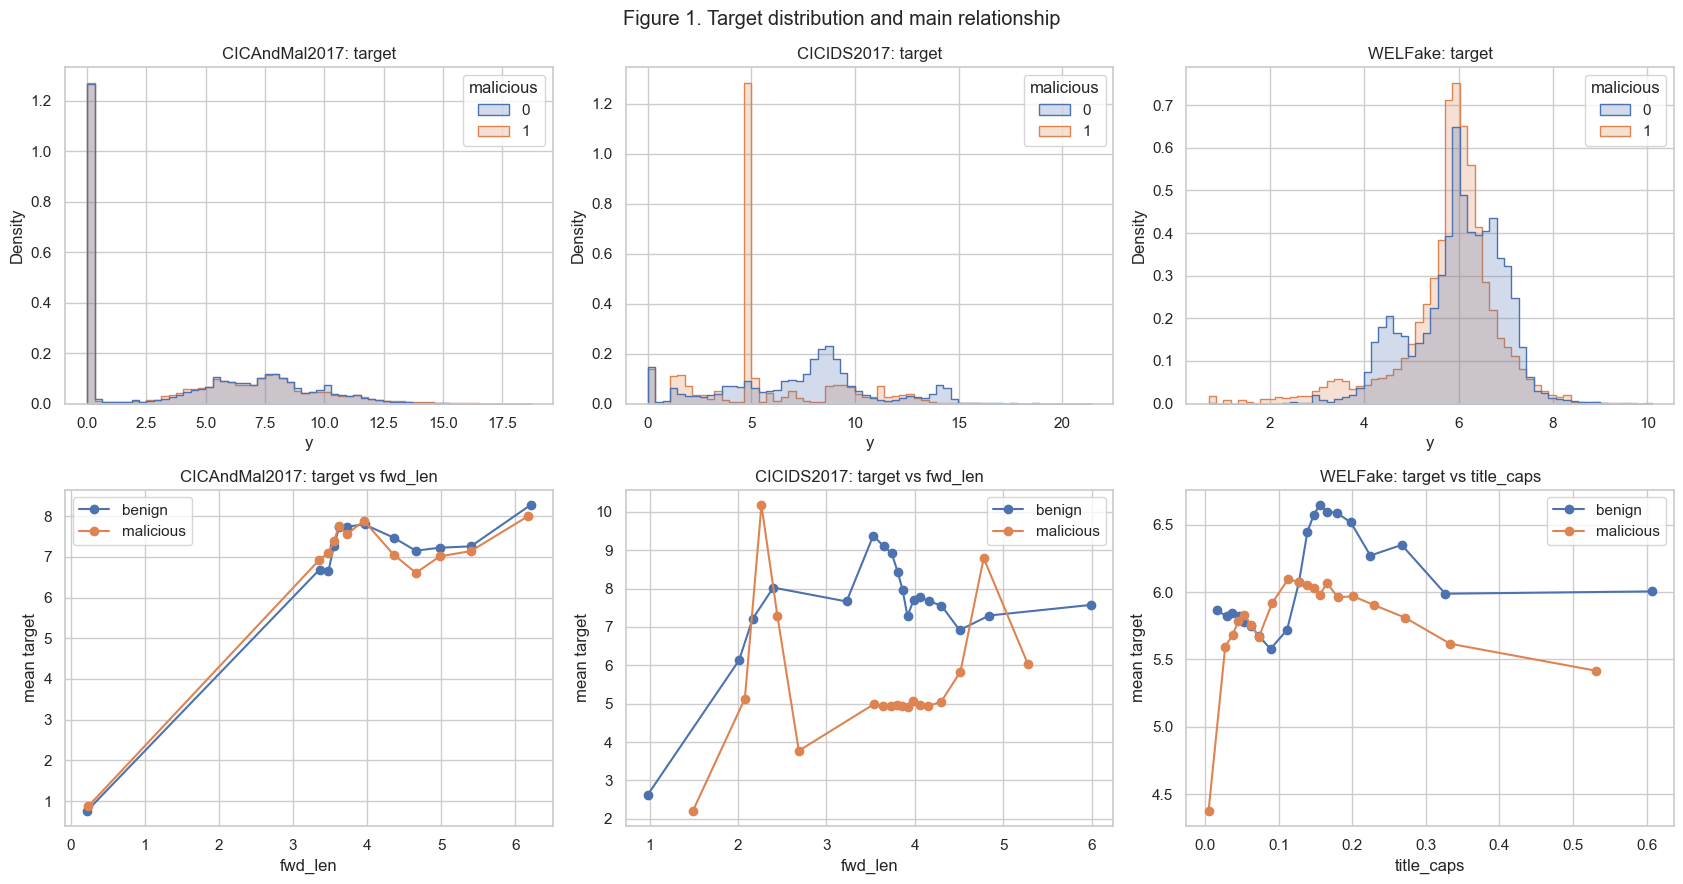

In [13]:
KEY = {"CICAndMal2017": "fwd_len", "CICIDS2017": "fwd_len", "WELFake": "title_caps"}

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, (name, (df, feats)) in enumerate(DATA.items()):
    sns.histplot(df, x="y", hue="malicious", bins=60, stat="density", common_norm=False, element="step", ax=axes[0, i])
    axes[0, i].set_title(f"{name}: target")
    df = df.assign(bin=pd.qcut(df[KEY[name]], 20, duplicates="drop"))
    means = df.groupby(["malicious", "bin"], observed=True)[[KEY[name], "y"]].mean().reset_index()
    for m, g in means.groupby("malicious"):
        axes[1, i].plot(g[KEY[name]], g["y"], "o-", label="malicious" if m else "benign")
    axes[1, i].set_xlabel(KEY[name]); axes[1, i].set_ylabel("mean target"); axes[1, i].legend()
    axes[1, i].set_title(f"{name}: target vs {KEY[name]}")
fig.suptitle("Figure 1. Target distribution and main relationship")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_eda.png", dpi=150); plt.show()

What this shows:
- The relationships are curved, not straight, so polynomial terms should help.
- In CICAndMal2017 the benign and malicious lines are almost the same. Malware traffic looks like normal app traffic.
- In CICIDS2017 the lines are very different. Attack traffic sits flat at a throughput of about 5 (log scale) no matter the packet size. This is the DoS flood pattern.
- In WELFake, fake articles have more capital letters in their titles, and the two lines go in different directions.

## 5. Multicollinearity
First a correlation matrix, then the VIF for each feature. VIF compares each feature to all the other features together, so it can catch a feature that is a combination of two others. The rule of thumb is that a VIF over 5 is a problem.

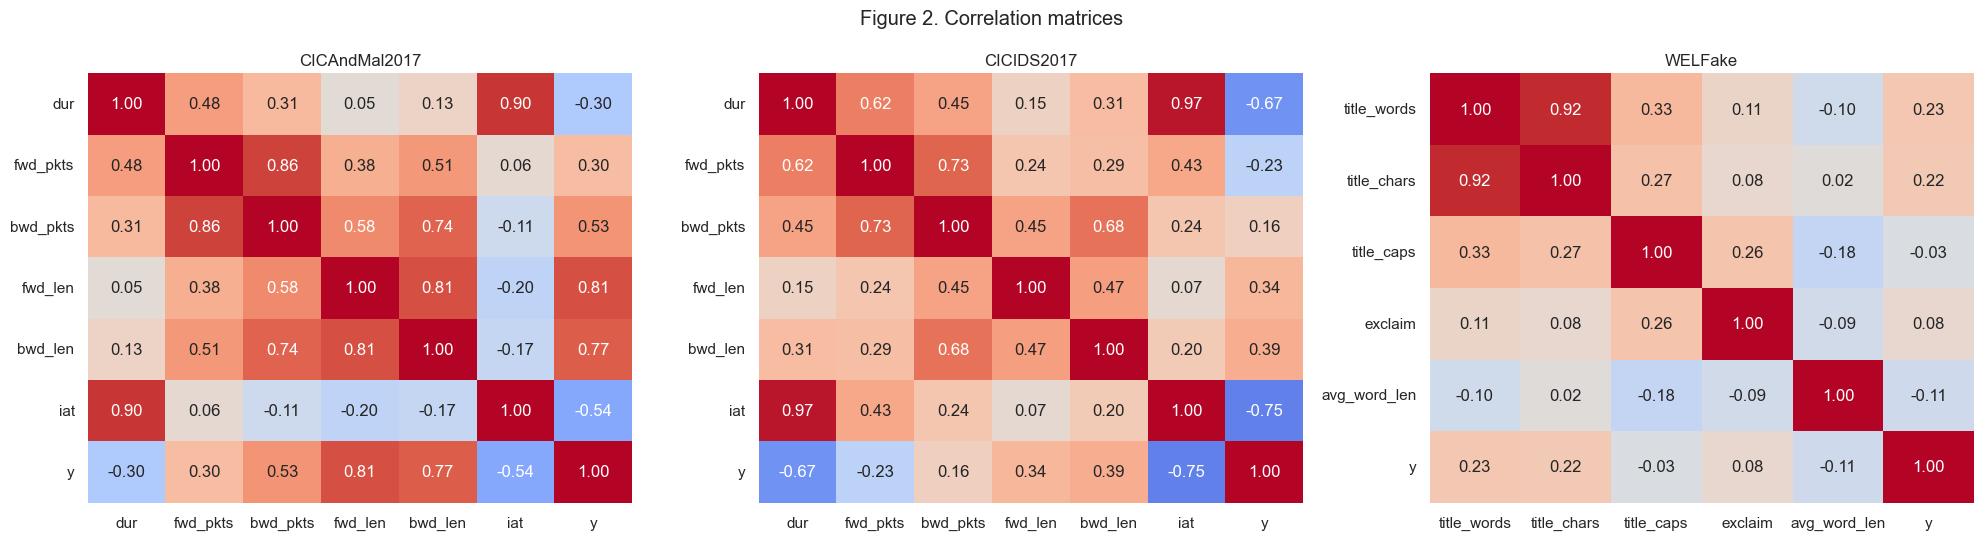

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (name, (df, feats)) in zip(axes, DATA.items()):
    sns.heatmap(df[feats + ["y"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=ax)
    ax.set_title(name)
fig.suptitle("Figure 2. Correlation matrices")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_corr.png", dpi=150); plt.show()

In [17]:
def vif(df, feats):
    X = sm.add_constant(df[feats])
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=feats)

for name, (df, feats) in DATA.items():
    print(name)
    print(vif(df, feats).round(1), "\n")

CICAndMal2017
dur        161.200
fwd_pkts    16.200
bwd_pkts    12.500
fwd_len      3.300
bwd_len      4.600
iat        132.900
dtype: float64 

CICIDS2017
dur        275.700
fwd_pkts    11.700
bwd_pkts     7.500
fwd_len      1.400
bwd_len      2.600
iat        207.300
dtype: float64 

WELFake
title_words    7.800
title_chars    7.600
title_caps     1.200
exclaim        1.100
avg_word_len   1.100
dtype: float64 



dur        275.700
fwd_pkts    11.700
bwd_pkts     7.500
fwd_len      1.400
bwd_len      2.600
iat        207.300
dtype: float64 

WELFake
title_words    7.800
title_chars    7.600
title_caps     1.200
exclaim        1.100
avg_word_len   1.100
dtype: float64 



Flow duration has a huge VIF in both network datasets. Mean inter-arrival time is about duration divided by the number of packets, so duration can be rebuilt from the other features. I drop duration. After that, backward packets is still above 5 in CICAndMal2017, so I drop it as well and use the same four features for both network datasets. In WELFake, title characters and title words carry the same information, so I drop title characters. The VIFs below are all under 5.

In [19]:
for name in ["CICAndMal2017", "CICIDS2017"]:
    print(name, "VIF without dur:", vif(DATA[name][0], ["fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat"]).round(1).to_dict())

FEATS = {"CICAndMal2017": ["fwd_pkts", "fwd_len", "bwd_len", "iat"],
         "CICIDS2017":    ["fwd_pkts", "fwd_len", "bwd_len", "iat"],
         "WELFake":       ["title_words", "title_caps", "exclaim", "avg_word_len"]}

for name, (df, _) in DATA.items():
    print(name, "final VIF:", vif(df, FEATS[name]).round(2).to_dict())

CICAndMal2017 VIF without dur: {'fwd_pkts': 4.7, 'bwd_pkts': 7.3, 'fwd_len': 2.9, 'bwd_len': 4.5, 'iat': 1.1}
CICIDS2017 VIF without dur: {'fwd_pkts': 3.1, 'bwd_pkts': 4.7, 'fwd_len': 1.3, 'bwd_len': 2.5, 'iat': 1.3}
CICAndMal2017 final VIF: {'fwd_pkts': 1.39, 'fwd_len': 2.91, 'bwd_len': 3.31, 'iat': 1.07}
CICIDS2017 final VIF: {'fwd_pkts': 1.32, 'fwd_len': 1.31, 'bwd_len': 1.36, 'iat': 1.24}
WELFake final VIF: {'title_words': 1.12, 'title_caps': 1.21, 'exclaim': 1.07, 'avg_word_len': 1.04}


CICAndMal2017 final VIF: {'fwd_pkts': 1.39, 'fwd_len': 2.91, 'bwd_len': 3.31, 'iat': 1.07}


CICIDS2017 final VIF: {'fwd_pkts': 1.32, 'fwd_len': 1.31, 'bwd_len': 1.36, 'iat': 1.24}
WELFake final VIF: {'title_words': 1.12, 'title_caps': 1.21, 'exclaim': 1.07, 'avg_word_len': 1.04}


## 6. Linear regression
I split each dataset 80/20 into train and test sets. The test set is only used for final scores. I fit the model with statsmodels (to see the coefficients) and check it against sklearn.

In [21]:
SPLITS = {}
for name, (df, _) in DATA.items():
    SPLITS[name] = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["malicious"])

results = []   # (dataset, model, test R2)
for name, (train, test) in SPLITS.items():
    f = FEATS[name]
    ols = sm.OLS(train["y"], sm.add_constant(train[f])).fit()
    lr = LinearRegression().fit(train[f], train["y"])
    test_r2 = r2_score(test["y"], lr.predict(test[f]))
    results.append((name, "1 linear", test_r2))
    print(f"{name}: train R2 = {ols.rsquared:.3f}, test R2 = {test_r2:.3f}, same coefs in sklearn: {np.allclose(ols.params[f], lr.coef_)}")
    print(ols.params.round(3).to_string(), "\n")

CICAndMal2017: train R2 = 0.834, test R2 = 0.833, same coefs in sklearn: True
const       7.667
fwd_pkts   -0.092
fwd_len     0.868
bwd_len     0.509
iat        -0.544 

CICIDS2017: train R2 = 0.896, test R2 = 0.895, same coefs in sklearn: True
const      13.183
fwd_pkts   -0.261
fwd_len     0.474
bwd_len     0.639
iat        -0.893 

WELFake: train R2 = 0.082, test R2 = 0.086, same coefs in sklearn: True
const           6.078
title_words     0.701
title_caps     -1.228
exclaim         0.181
avg_word_len   -0.294 



A straight-line model explains 83% of the variation in CICAndMal2017 and 90% in CICIDS2017, but only 9% in WELFake. Train and test R2 are almost equal, so there is no overfitting yet. Packet size (fwd_len) and time between packets (iat) are the biggest drivers in both network datasets, which matches the Module B random forest. Because everything is logged, a slope of 0.87 means a 1% bigger packet gives about 0.87% more bytes per second.

## 7. Polynomial terms
Following the lesson, polynomial terms are added as new columns (x squared, x cubed, and so on) with pd.concat, then fit with sm.OLS. Each feature is centered first (its training mean is subtracted). Section 7b shows why this matters.

In [24]:
def add_powers(df_X, degree):
    # Lesson approach: add columns for x**2, x**3, ... next to the original columns
    cols = list(df_X.columns)
    parts = [df_X]
    for d in range(2, degree + 1):
        parts.append((df_X ** d).rename(columns={f"{var}": f"{var}{d}" for var in cols}))
    return pd.concat(parts, axis=1)

# Centered copies of the train and test sets (centered on the training mean)
CENTERED = {}
for name, (train, test) in SPLITS.items():
    means = train[FEATS[name]].mean()
    train_c, test_c = train.copy(), test.copy()
    train_c[FEATS[name]] = train[FEATS[name]] - means
    test_c[FEATS[name]] = test[FEATS[name]] - means
    CENTERED[name] = (train_c, test_c)

### 7a. Why not use a very high degree?
Like the lesson example, I take only 100 flows and fit polynomials of higher and higher degree in forward packet length. I then score each fit on 20,000 other flows.

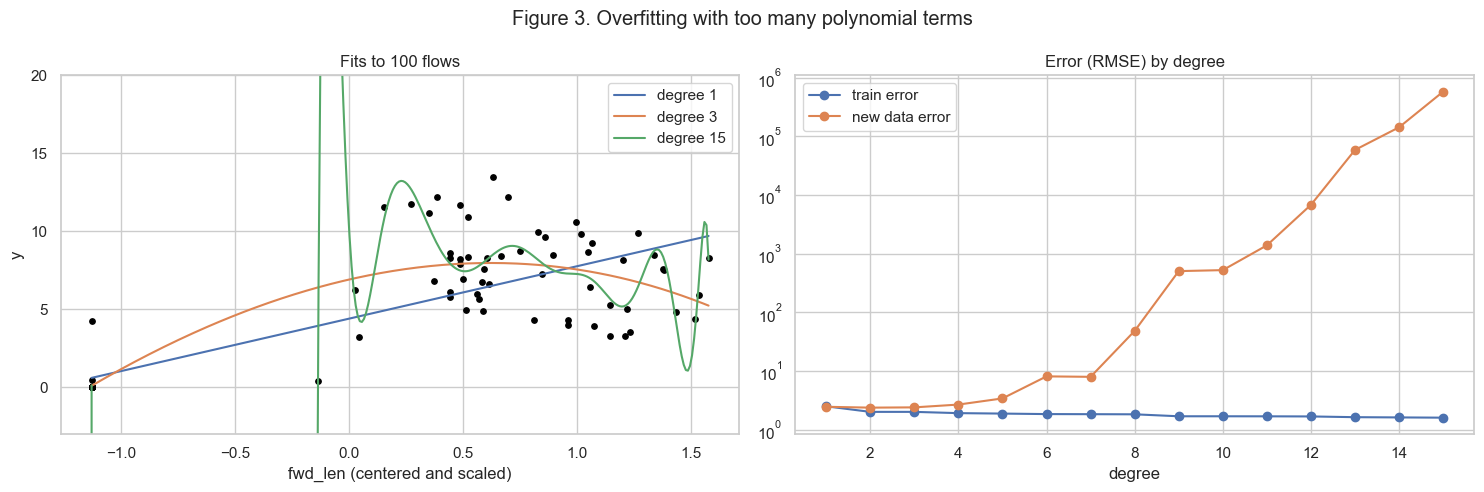

degree,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
train error,2.500,2.010,2.010,1.910,1.880,1.840,1.830,1.830,1.690,1.690,1.690,1.680,1.630,1.620,1.600
new data error,2.450,2.370,2.400,2.680,3.410,8.100,7.960,48.310,505.020,524.950,1389.240,6820.050,58860.990,143158.050,580350.180


In [26]:
train_c, test_c = CENTERED["CICAndMal2017"]
small = train_c.sample(100, random_state=7)
other = test_c.sample(20000, random_state=7)
std = small["fwd_len"].std()
x_small = (small[["fwd_len"]] / std)          # scaled so high powers stay manageable
x_other = (other[["fwd_len"]] / std)

rows, fits = [], {}
for deg in range(1, 16):
    results_deg = sm.OLS(small["y"], sm.add_constant(add_powers(x_small, deg))).fit()
    fits[deg] = results_deg
    pred_small = results_deg.predict(sm.add_constant(add_powers(x_small, deg)))
    pred_other = results_deg.predict(sm.add_constant(add_powers(x_other, deg), has_constant="add"))
    rows.append({"degree": deg,
                 "train error": np.sqrt(np.mean((pred_small - small["y"]) ** 2)),
                 "new data error": np.sqrt(np.mean((pred_other - other["y"]) ** 2))})
errors = pd.DataFrame(rows).set_index("degree")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
grid = pd.DataFrame({"fwd_len": np.linspace(x_small["fwd_len"].min(), x_small["fwd_len"].max(), 300)})
axes[0].scatter(x_small["fwd_len"], small["y"], color="black", s=15)
for deg in [1, 3, 15]:
    axes[0].plot(grid["fwd_len"], fits[deg].predict(sm.add_constant(add_powers(grid, deg))), label=f"degree {deg}")
axes[0].set_ylim(-3, 20); axes[0].legend(); axes[0].set_title("Fits to 100 flows")
axes[0].set_xlabel("fwd_len (centered and scaled)"); axes[0].set_ylabel("y")
errors.plot(ax=axes[1], marker="o", logy=True); axes[1].set_title("Error (RMSE) by degree")
fig.suptitle("Figure 3. Overfitting with too many polynomial terms")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_overfit.png", dpi=150); plt.show()
errors.round(2).T

With only 100 samples, the training error keeps going down as the degree goes up. The error on new data is lowest at degree 2 and then blows up (over 500,000 at degree 15). The high-degree curves swing wildly between the data points. This is why the degree has to be chosen on data the model has not seen.

### 7b. X and X squared are collinear
The lesson warns that X and X squared are almost the same when X has a small range. Centering X (subtracting the mean) before squaring fixes this.

In [29]:
for name, (train, test) in SPLITS.items():
    x = train[KEY[name]]
    raw = pd.DataFrame({"x": x, "x2": x ** 2})
    xc = x - x.mean()
    centered = pd.DataFrame({"x": xc, "x2": xc ** 2})
    print(f"{name}: VIF raw = {vif(raw, ['x', 'x2'])['x']:.1f}, VIF centered = {vif(centered, ['x', 'x2'])['x']:.1f}")

CICAndMal2017: VIF raw = 11.7, VIF centered = 1.0
CICIDS2017: VIF raw = 8.9, VIF centered = 1.1
WELFake: VIF raw = 5.3, VIF centered = 2.0


### 7c. Pick the degree with cross-validation
The polynomial degree is the hyperparameter. For degrees 1 to 4, I add the power columns and run 5-fold cross-validation on the training set only, using a 50,000 row sample to save time. Then I fit the chosen degree with sm.OLS on the full training set and score it on the test set.

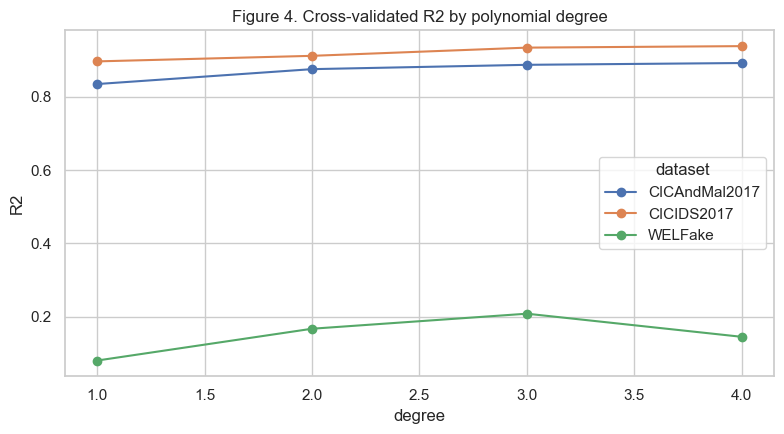

dataset,CICAndMal2017,CICIDS2017,WELFake
degree,,,
1,0.834,0.896,0.081
2,0.875,0.911,0.168
3,0.886,0.933,0.209
4,0.891,0.937,0.146


In [31]:
cv_rows = []
for name, (train_c, test_c) in CENTERED.items():
    sample = train_c.sample(min(50000, len(train_c)), random_state=SEED)
    for deg in range(1, 5):
        X = add_powers(sample[FEATS[name]], deg)
        scores = cross_val_score(LinearRegression(), X, sample["y"], cv=5, scoring="r2")
        cv_rows.append({"dataset": name, "degree": deg, "cv R2": scores.mean()})
cv = pd.DataFrame(cv_rows).pivot(index="degree", columns="dataset", values="cv R2")

cv.plot(marker="o", figsize=(8, 4.5), title="Figure 4. Cross-validated R2 by polynomial degree")
plt.ylabel("R2"); plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_degree_cv.png", dpi=150); plt.show()
cv

In [32]:
BEST_DEG = {name: int(cv[name].idxmax()) for name in cv.columns}
print("Chosen degree:", BEST_DEG)

for name, (train_c, test_c) in CENTERED.items():
    X_train = sm.add_constant(add_powers(train_c[FEATS[name]], BEST_DEG[name]))
    X_test = sm.add_constant(add_powers(test_c[FEATS[name]], BEST_DEG[name]))
    results_poly = sm.OLS(train_c["y"], X_train).fit()
    test_r2 = r2_score(test_c["y"], results_poly.predict(X_test))
    results.append((name, "2 polynomial", test_r2))
    print(f"{name}: train R2 = {results_poly.rsquared:.3f}, test R2 = {test_r2:.3f}")

Chosen degree: {'CICAndMal2017': 4, 'CICIDS2017': 4, 'WELFake': 3}
CICAndMal2017: train R2 = 0.891, test R2 = 0.889
CICIDS2017: train R2 = 0.938, test R2 = 0.937
WELFake: train R2 = 0.210, test R2 = 0.217


CICIDS2017: train R2 = 0.938, test R2 = 0.937
WELFake: train R2 = 0.210, test R2 = 0.217


Results:
- Centering removes the X and X squared problem (VIF drops from about 12 to 1).
- Adding squared, cubed and fourth-power columns improves the network models: test R2 goes from 0.833 to 0.889 for CICAndMal2017 and from 0.895 to 0.937 for CICIDS2017. Train and test R2 stay almost equal, so there is no overfitting. With about 240,000 rows there is plenty of data for the extra columns.
- WELFake improves from 0.09 to 0.22 at degree 3, then gets worse at degree 4 (0.21 to 0.15 in cross-validation). That is where overfitting starts.
- Cross-validation picked degree 4 for the network data and degree 3 for WELFake.
- The gain from degree 3 to 4 is small, so degree 3 would also be a reasonable, simpler choice.

## 8. Interaction terms
### 8a. Feature times malicious
An interaction term is a new column made by multiplying two features. Here each feature is multiplied by the 0/1 malicious column, so malicious data gets its own slope. Example: y = b0 + b1 x + b2 malicious + b3 (x times malicious). For benign data the slope of x is b1, and for malicious data it is b1 + b3.

The features are already centered, which keeps the interaction columns from being collinear with the main features. I compare the model with interactions to the model without them using an F-test and test R2.

Note: with this many rows almost every p-value is tiny, so I focus on the size of the slopes and the change in test R2.

In [35]:
def add_interactions(df, feats):
    X = df[feats + ["malicious"]].copy()
    for c in feats:
        X[c + "_x_mal"] = df[c] * df["malicious"]
    return X

INTER = {}
slopes = {}
for name, (train_c, test_c) in CENTERED.items():
    f = FEATS[name]
    plain = sm.OLS(train_c["y"], sm.add_constant(train_c[f + ["malicious"]])).fit()
    inter = sm.OLS(train_c["y"], sm.add_constant(add_interactions(train_c, f))).fit()
    INTER[name] = (inter, train_c)
    results.append((name, "3 linear + malicious", r2_score(test_c["y"], plain.predict(sm.add_constant(test_c[f + ["malicious"]])))))
    results.append((name, "4 linear x malicious", r2_score(test_c["y"], inter.predict(sm.add_constant(add_interactions(test_c, f))))))
    F, p, df_diff = inter.compare_f_test(plain)
    print(f"{name}: test R2 {results[-2][2]:.4f} -> {results[-1][2]:.4f}, F = {F:.0f}")
    slopes[name] = pd.DataFrame({"benign slope": [inter.params[c] for c in f],
                                 "malicious slope": [inter.params[c] + inter.params[c + "_x_mal"] for c in f]}, index=f)
    print(slopes[name].round(3), "\n")

CICAndMal2017: test R2 0.8331 -> 0.8336, F = 174
          benign slope  malicious slope
fwd_pkts        -0.021           -0.111
fwd_len          0.734            0.898
bwd_len          0.566            0.495
iat             -0.577           -0.539 

CICIDS2017: test R2 0.9003 -> 0.9150, F = 9873
          benign slope  malicious slope
fwd_pkts        -0.030           -1.495
fwd_len          0.831            0.352
bwd_len          0.468            0.655
iat             -0.977           -0.769 

WELFake: test R2 0.0955 -> 0.1290, F = 516
              benign slope  malicious slope
title_words          0.640            0.607
title_caps           2.668           -1.219
exclaim              0.476            0.134
avg_word_len        -0.485           -0.074 



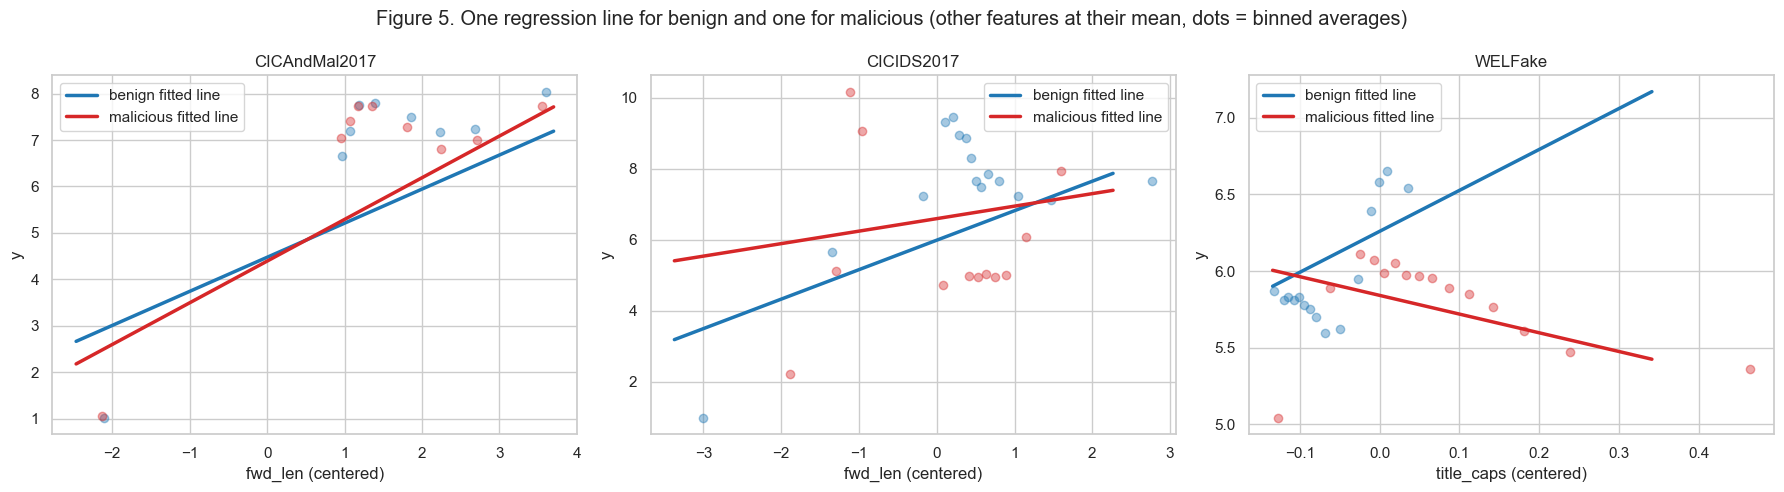

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (model, train_c)) in zip(axes, INTER.items()):
    k = KEY[name]
    x = np.linspace(train_c[k].quantile(0.02), train_c[k].quantile(0.98), 50)
    for m, color in [(0, "tab:blue"), (1, "tab:red")]:
        line = model.params["const"] + m * model.params["malicious"] + (model.params[k] + m * model.params[k + "_x_mal"]) * x
        ax.plot(x, line, color=color, lw=2.5, label=("malicious" if m else "benign") + " fitted line")
        g = train_c[train_c["malicious"] == m]
        b = g.groupby(pd.qcut(g[k], 15, duplicates="drop"), observed=True)[[k, "y"]].mean()
        ax.scatter(b[k], b["y"], color=color, alpha=0.4)
    ax.set_xlabel(k + " (centered)"); ax.set_ylabel("y"); ax.set_title(name); ax.legend()
fig.suptitle("Figure 5. One regression line for benign and one for malicious (other features at their mean, dots = binned averages)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_interaction.png", dpi=150); plt.show()

Results:
- CICIDS2017: adding the interactions raises test R2 from 0.900 to 0.915 (F = 9,873). For benign traffic the packet size slope is 0.83, for attacks only 0.35. Attacks send many small fixed-size packets, so throughput does not grow with packet size.
- CICAndMal2017: the interactions add almost nothing (test R2 0.833 to 0.834). Malware follows nearly the same pattern as benign traffic.
- WELFake: the interactions raise test R2 from 0.096 to 0.129. In real news, titles with more capitals go with longer articles. In fake news it is the opposite.
- Interaction terms need much more data than main effects (about 16 times, per the lesson). Every group here has tens of thousands of rows, so sample size is not a concern.

### 8b. Categorical feature: one slope per attack type
Now the 0/1 label is replaced by the category, one-hot encoded with Benign as the baseline (like the lesson's Animal, Mineral, Vegetable example). Each category column is multiplied by forward packet length, so every category gets its own slope. Categories with fewer than 500 flows are left out. This is done for the two network datasets because WELFake only has two classes.

         Adware  Ransomware  SMSmalware  Scareware
2264829       0           0           0          1
1432292       1           0           0          0
1250447       1           0           0          0 

CICAndMal2017 {'Benign': 0.819, 'Adware': 0.861, 'Ransomware': 0.916, 'SMSmalware': 0.889, 'Scareware': 0.857}
CICIDS2017 {'Benign': 0.74, 'BruteForce': 0.942, 'DoS/DDoS': 0.317, 'PortScan': 2.003, 'WebAttack': 0.533}


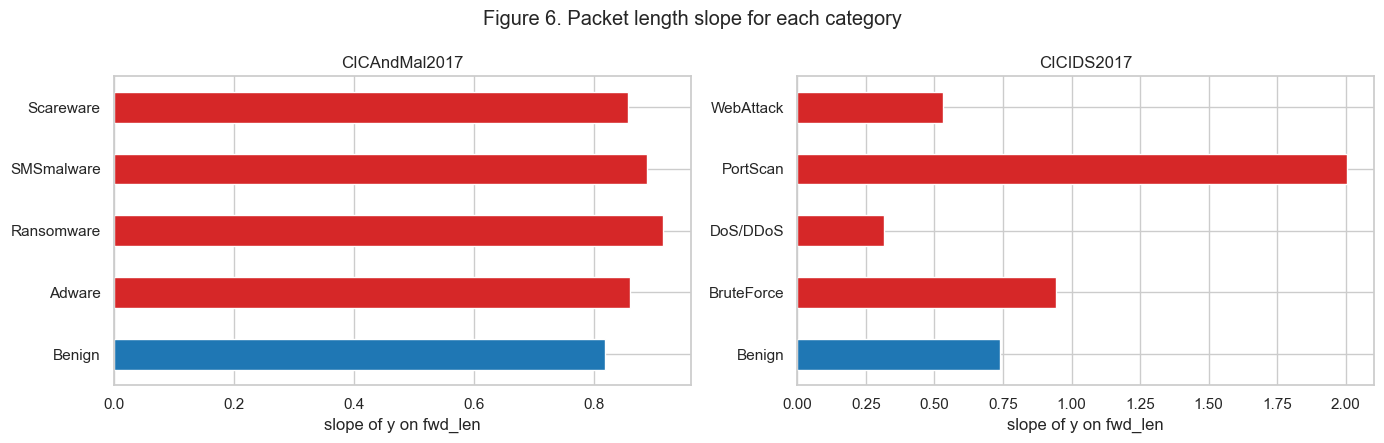

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, ["CICAndMal2017", "CICIDS2017"]):
    train_c = CENTERED[name][0]
    counts = train_c["category"].value_counts()
    train_c = train_c[train_c["category"].isin(counts[counts >= 500].index)]

    dummies = pd.get_dummies(train_c["category"]).drop(columns="Benign").astype(int)   # Benign = baseline
    X = pd.concat([train_c[FEATS[name]], dummies], axis=1)
    for cat in dummies.columns:
        X["fwd_len_x_" + cat] = train_c["fwd_len"] * dummies[cat]
    if name == "CICAndMal2017":
        print(dummies.head(3), "\n")
    m = sm.OLS(train_c["y"], sm.add_constant(X)).fit()

    cat_slopes = {"Benign": m.params["fwd_len"]}
    for cat in dummies.columns:
        cat_slopes[cat] = m.params["fwd_len"] + m.params["fwd_len_x_" + cat]
    cat_slopes = pd.Series(cat_slopes)
    cat_slopes.plot.barh(ax=ax, color=["tab:blue"] + ["tab:red"] * (len(cat_slopes) - 1))
    ax.set_title(name); ax.set_xlabel("slope of y on fwd_len")
    print(name, cat_slopes.round(3).to_dict())
fig.suptitle("Figure 6. Packet length slope for each category")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_category_slopes.png", dpi=150); plt.show()

In CICAndMal2017 all malware families have slopes close to benign (0.82 to 0.92), with ransomware the furthest away. In CICIDS2017 the attack types go in different directions: DoS is much flatter than benign (0.32 vs 0.74), and PortScan is much steeper (2.0). So malicious is not a single pattern even inside one dataset. In Module C, the SHAP comparison should be done per attack type and not only for malicious vs benign.

## 9. Using linear regression on the 0/1 label
The capstone's real goal is to classify malicious vs benign. The lesson warns that linear regression on a 0/1 target can give answers below 0 or above 1. I test this by fitting sm.OLS on the features plus their squares to predict the malicious label directly.

CICAndMal2017: 0.2% of predictions outside 0-1, accuracy = 0.800, share malicious = 0.80
CICIDS2017: 24.1% of predictions outside 0-1, accuracy = 0.910, share malicious = 0.50
WELFake: 14.1% of predictions outside 0-1, accuracy = 0.823, share malicious = 0.45


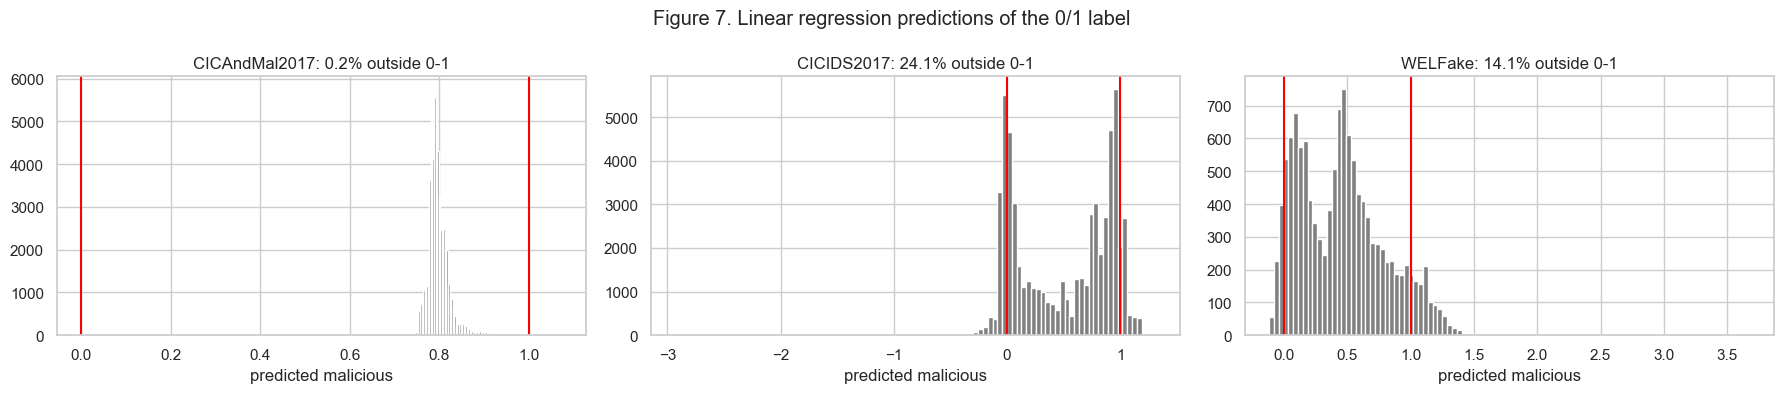

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, (train_c, test_c)) in zip(axes, CENTERED.items()):
    f = FEATS[name]
    lpm = sm.OLS(train_c["malicious"], sm.add_constant(add_powers(train_c[f], 2))).fit()
    p = lpm.predict(sm.add_constant(add_powers(test_c[f], 2)))
    outside = np.mean((p < 0) | (p > 1))
    accuracy = np.mean((p > 0.5) == test_c["malicious"])
    print(f"{name}: {outside:.1%} of predictions outside 0-1, accuracy = {accuracy:.3f}, share malicious = {test_c['malicious'].mean():.2f}")
    ax.hist(p, bins=100, color="gray"); ax.axvline(0, color="red"); ax.axvline(1, color="red")
    ax.set_title(f"{name}: {outside:.1%} outside 0-1"); ax.set_xlabel("predicted malicious")
fig.suptitle("Figure 7. Linear regression predictions of the 0/1 label")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_lpm.png", dpi=150); plt.show()

Results:
- CICIDS2017 and WELFake: 24% and 14% of the predictions are below 0 or above 1. They cannot be read as probabilities, which is the problem the lesson describes. Logistic regression (Week 4) fixes this.
- WELFake reaches 82% accuracy from just four simple title and text features. Capital letters in the title are a strong fake news signal.
- CICAndMal2017 gets 80% accuracy, but that is the same as the share of malware in the sample, so the model is just guessing malware for everything. Flow-level malware detection will be the hardest part of the capstone. My F1 target of 0.85 for this dataset may need more features or a different approach.

## 10. Summary of results

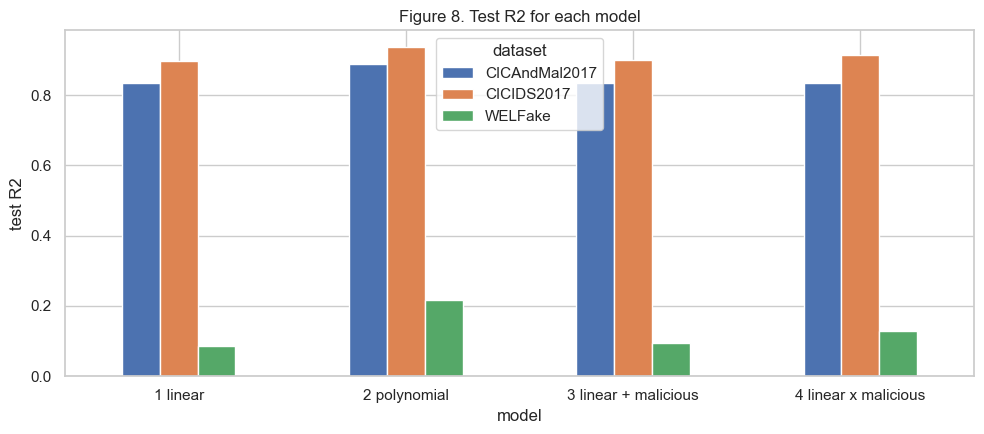

dataset,CICAndMal2017,CICIDS2017,WELFake
model,,,
1 linear,0.833,0.895,0.086
2 polynomial,0.889,0.937,0.217
3 linear + malicious,0.833,0.900,0.096
4 linear x malicious,0.834,0.915,0.129


In [45]:
summary = pd.DataFrame(results, columns=["dataset", "model", "test R2"]).pivot(index="model", columns="dataset", values="test R2")
summary.plot.bar(figsize=(10, 4.5), rot=0, title="Figure 8. Test R2 for each model")
plt.ylabel("test R2"); plt.tight_layout(); plt.savefig(FIG_DIR / "fig8_summary.png", dpi=150); plt.show()
summary

In [46]:
# Does malicious traffic change the slopes in the same direction in both network datasets?
change = pd.DataFrame({name: slopes[name]["malicious slope"] - slopes[name]["benign slope"] for name in ["CICAndMal2017", "CICIDS2017"]})
change["same direction"] = np.sign(change["CICAndMal2017"]) == np.sign(change["CICIDS2017"])
change

,CICAndMal2017,CICIDS2017,same direction
fwd_pkts,-0.090,-1.464,True
fwd_len,0.164,-0.479,False
bwd_len,-0.070,0.187,False
iat,0.038,0.208,True


Week 1 conclusions:
1. Multicollinearity: VIF found that flow duration can be rebuilt from the other features (VIF over 160), and title characters duplicate title words. Dropping them gave stable features with all VIFs under 5.
2. Polynomial terms: they improved every dataset (for example CICIDS2017 went from 0.895 to 0.937 test R2). Cross-validation picked degree 4 for the network data and 3 for WELFake. Overfitting was controlled with a train/test split and cross-validation, and shown directly with the 100-sample example.
3. Interaction terms: malicious data changes the slopes a lot in CICIDS2017 and WELFake, but barely in CICAndMal2017. The slope changes in the two network datasets go the same way for only 2 of 4 features. So far the evidence points to domain-specific patterns rather than one universal fingerprint. Module C will test this properly with SHAP.
4. A 0/1 target needs logistic regression, not linear regression.

Expected: packet size and timing matter most, and curves help the fit. Unexpected: how hard it is to tell malware from benign app traffic, how differently attack types behave inside CICIDS2017, and how much title capital letters reveal about fake news.

## 11. Notes for the Milestone One write-up
| Rubric item | What I did |
|---|---|
| Avoiding overfitting | 80/20 train/test split, 5-fold cross-validation to pick the degree, and the 100-sample demo in section 7a |
| Metrics | R2 on the test set, F-test for the interaction terms |
| Hyperparameter tuning | Polynomial degree 1 to 4 (power columns added with pd.concat) chosen by cross-validation, VIF cutoff of 5 for dropping features |
| How EDA helped | Module B heatmaps pointed to the packet count collinearity, skewed data led to the log transform, Figure 1 showed curves and different slopes before modeling |